# SDXL × DrawBench — Qualitative Results

Side-by-side comparison of both sampling strategies 

In [1]:
from pathlib import Path
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

In [2]:
IMAGES_DIR = Path("sdxl_drawbench_images")
STANDARD_DIR = IMAGES_DIR / "sdxl_drawbench"
ZSAMPLING_DIR = IMAGES_DIR / "sdxl_drawbench_zsampling"

CSV_PATH = Path("sdxl_drawbench_eval_results.csv")

NUM_SAMPLES = 6
RNG_SEED = 42

In [3]:
df = pd.read_csv(CSV_PATH)
print(f"Total evaluation pairs: {len(df)}")
df.head()

Total evaluation pairs: 600


,prompt_idx,seed,prompt,hps_standard,hps_zsampling,aes_standard,aes_zsampling,pick_standard,pick_zsampling,ir_standard,ir_zsampling
0,0,42,A red colored car.,0.248169,0.274902,5.458159,5.899829,0.231843,0.238453,NaN,NaN
1,1,42,A black colored car.,0.240601,0.262451,5.155932,5.635019,0.229252,0.229904,NaN,NaN
2,2,42,A pink colored car.,0.289551,0.315186,5.613592,6.077298,0.248128,0.251805,NaN,NaN
3,3,42,A black colored dog.,0.274170,0.296387,5.727967,5.880596,0.235219,0.235844,NaN,NaN
4,4,42,A red colored dog.,0.302734,0.312012,5.382696,6.095802,0.230009,0.237310,NaN,NaN


In [4]:
def index_images(base_dir: Path) -> dict[str, Path]:
    """Build filename -> path index across all checkpoint subfolders."""
    return {p.name: p for p in base_dir.rglob("*.png")}

std_index = index_images(STANDARD_DIR)
zs_index = index_images(ZSAMPLING_DIR)

print(f"Standard images: {len(std_index)}")
print(f"Z-Sampling images: {len(zs_index)}")

Standard images: 600
Z-Sampling images: 600


In [5]:
rng = np.random.default_rng(RNG_SEED)
sample_indices = rng.choice(len(df), size=NUM_SAMPLES, replace=False)
samples = df.iloc[sample_indices].reset_index(drop=True)

print("Selected prompts:")
for _, row in samples.iterrows():
    print(f"  [{row['prompt_idx']:03d}, seed={row['seed']}] {row['prompt']}")

Selected prompts:
  [190, seed=123] A sign that says 'Deep Learning'.
  [061, seed=2026] A single clock is sitting on a table.
  [059, seed=123] A cube made of brick. A cube with the texture of brick.
  [115, seed=2026] A wine glass on top of a dog.
  [062, seed=123] A couple of glasses are sitting on a table.
  [053, seed=42] Three cats and three dogs sitting on the grass.


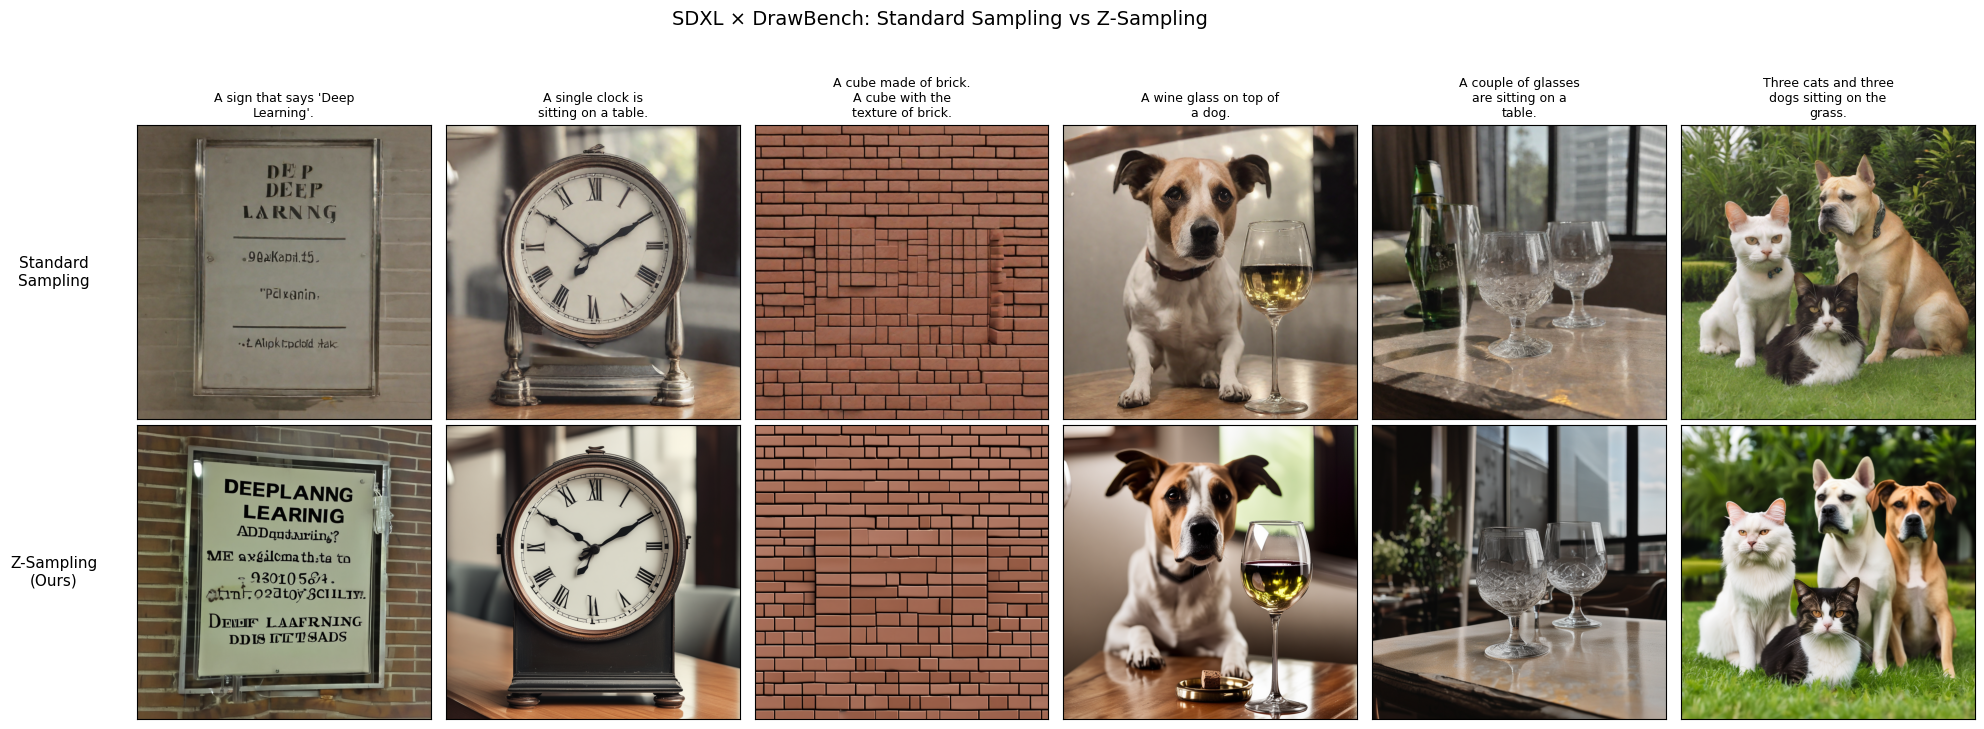

In [6]:
fig, axes = plt.subplots(2, NUM_SAMPLES, figsize=(3.5 * NUM_SAMPLES, 7.5))

for col, (_, row) in enumerate(samples.iterrows()):
    idx = int(row["prompt_idx"])
    seed = int(row["seed"])
    prompt = row["prompt"]

    std_fname = f"sdxl_prompt{idx:03d}_seed{seed}.png"
    zs_fname = f"sdxl_zsample_prompt{idx:03d}_seed{seed}.png"

    std_img = Image.open(std_index[std_fname])
    zs_img = Image.open(zs_index[zs_fname])

    axes[0, col].imshow(std_img)
    axes[1, col].imshow(zs_img)

    wrapped = "\n".join(textwrap.wrap(prompt, width=22))
    axes[0, col].set_title(wrapped, fontsize=9, pad=6)

    for ax in (axes[0, col], axes[1, col]):
        ax.set_xticks([])
        ax.set_yticks([])

axes[0, 0].set_ylabel("Standard\nSampling", fontsize=11, rotation=0, labelpad=60, va="center")
axes[1, 0].set_ylabel("Z-Sampling\n(Ours)", fontsize=11, rotation=0, labelpad=60, va="center")

fig.suptitle("SDXL × DrawBench: Standard Sampling vs Z-Sampling", fontsize=14, y=0.98)
plt.tight_layout(rect=[0.05, 0, 1, 0.95])
plt.savefig("sdxl_drawbench_qualitative.png", dpi=150, bbox_inches="tight")
plt.show()